# Week 4 · Mini-project: predicting defects, end to end

Everything from Weeks 2–4 in one realistic task, in the order a real project (and an exam's "design an ML pipeline" question) goes. The data, `factory_parts.csv` in this folder, is a production log of 3000 parts: sensor readings, line, shift, material, operator experience, and whether the part turned out **defective (4.8%)**. It's synthetic but built like your KAMP data: rare positives, missing sensor values, and a hidden interaction for you to find. Run each cell, read the result, and answer the ✏️ questions in your own words; §11 collects those answers into a short write-up.

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## Words you'll see
- **ColumnTransformer**: Applies different preprocessing to different columns (scale the numbers, one-hot the categories) and glues the results side by side.
- **PR-AUC / average precision**: The area under the precision–recall curve. With rare positives it's the honest score; random guessing gets the positive rate (here 0.048).
- **out-of-fold predictions**: Predictions for each training row from a model that never saw that row (cross_val_predict). Safe for choosing a threshold without touching the test set.
- **feature engineering**: Making new columns from domain knowledge, e.g. "night shift AND hot".

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from figures import *
import warnings; warnings.simplefilter("ignore")
import checks; checks.load(globals(), "05")      # defines check(n)

## M. The map: what's in this notebook and why

🖼 **Picture.** The order of a project. Each box is one section. The test set is touched exactly once, in §9.

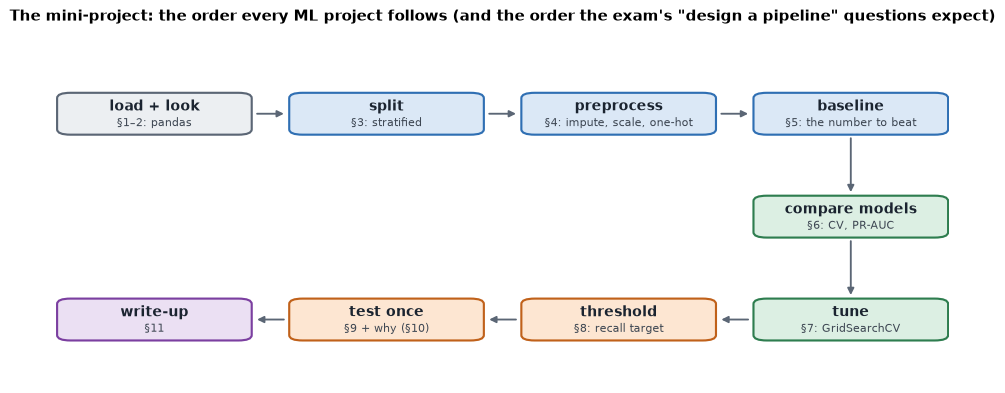

In [2]:
fig_project_map()

| Section | Step | Why it's here |
|---|---|---|
| E | start from the end | the **finished** pipeline scoring one new part: what you're building, before you build it |
| 1–2 | load and look; ask questions with `groupby` | you can't model what you haven't looked at; this is where the best idea of the project comes from |
| 3 | split, stratified | set the test set aside before anything learns from the data |
| 4 | preprocess in a pipeline | missing values, scaling and one-hot, fitted on training folds only (no leakage) |
| 5 | baseline | the number any model has to beat, and why accuracy is useless here |
| 6 | compare models with CV | logistic vs random forest vs gradient boosting, scored by PR-AUC |
| 7 | tune, and engineer features | what actually helps more: settings or better inputs? |
| 8 | choose a threshold | turn probabilities into alarms that meet a recall target |
| 9–10 | test once; one new part by hand; what drives it | the honest final number, the section E calculation redone from the fitted model, and which features matter |
| 11 | write-up | five sentences a manager (or an examiner) can read |
| 12 | from scratch alongside the package | your own logistic regression on the same inputs, against scikit-learn's |

## 0. Recap first · 10 min, closed book

**Quick check:** A test set has 4.8% positives. A model always says "negative". Its accuracy, recall and average precision?

<details><summary>Answer</summary>

Accuracy 0.952, recall 0, average precision ≈ 0.048 (the positive rate: it ranks nothing). [Week 3 · 01 §10 ↗](../week3/01_logistic_regression_in_pictures.ipynb)

</details>

**Quick check:** Why must the scaler be fitted on the training data only?

<details><summary>Answer</summary>

Fitting on all the data lets test-set statistics leak into training, so the test score looks better than it is. A pipeline inside CV handles it. [Week 2 · 05 §4 ↗](../week2/05_logistic_regression_knn.ipynb)

</details>

**Quick check:** `pd.get_dummies` on a column `line` with values A, B, C produces which columns?

<details><summary>Answer</summary>

`line_A`, `line_B`, `line_C`, each 0/1. [Week 3 · 03 §10 ↗](../week3/03_pandas_methods.ipynb)

</details>

**Quick check:** Lowering the threshold: what happens to recall and (usually) precision?

<details><summary>Answer</summary>

Recall goes up (or stays the same); precision usually goes down. [Week 3 · 01 §9 ↗](../week3/01_logistic_regression_in_pictures.ipynb)

</details>

**Quick check:** Bagging vs boosting in one line each.

<details><summary>Answer</summary>

Bagging: average many deep trees trained on bootstrap samples (cuts variance). Boosting: add small trees one at a time, each fixing what's still wrong (cuts bias). [01 §12 ↗](01_boosting_step_by_step.ipynb)

</details>

## E. Start from the end: the finished pipeline scores one new part

As in the other notebooks this week: **first the finished model and what it does with a new input.** Here the model is a whole pipeline. This is where the project ends up:

🖼 **Picture.** One new part (night shift, 76.5 °C, material M3, line D, humidity sensor missing) going through the finished pipeline. Every number used along the way was **stored during training**.

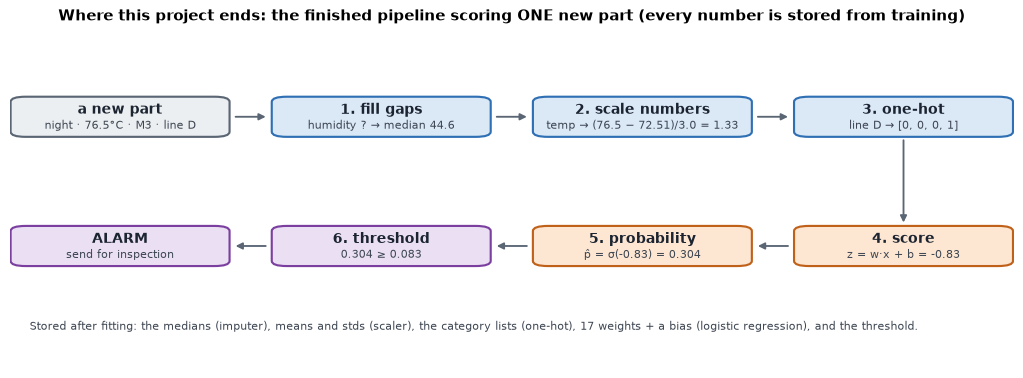

In [3]:
fig_project_end()

| Stage | What's stored after fitting | What it does to the new part | Built in |
|---|---|---|---|
| impute | the training **median** of each numeric column | missing humidity → 44.6 | §4 |
| scale | the training **mean** and **std** of each numeric column | temp → $\frac{76.5 - 72.51}{3.00} = 1.33$ | §4 |
| one-hot | the list of categories seen in training | line D → `[0, 0, 0, 1]`, night → `[0, 1]`, M3 → `[0, 0, 1]` | §4 |
| logistic regression | 17 weights and a bias | $z = w^\top x + b = -0.83$, so $\hat p = 0.304$ | §6–7 |
| threshold | one number, chosen on training data | $0.304 \ge 0.083$ → **alarm** | §8 |

**Every stage only uses numbers learned from the training set**, which is exactly why the split has to come first (§3). Read §1–8 as building these five rows; in §9 you'll redo this part's calculation by hand from the fitted model and get the same 0.304.

## 1. Load and look

In [4]:
df = pd.read_csv("factory_parts.csv")
print(df.shape)                                  # → (3000, 12)
print(round(df["defect"].mean(), 4), df["defect"].sum())   # → 0.048 144     4.8% defective: rare
print(df.isna().sum()[lambda s: s > 0].to_dict())          # → {'temp': 86, 'humidity': 150, 'vibration': 56}

(3000, 12)
0.048 144
{'temp': 86, 'humidity': 150, 'vibration': 56}


In [5]:
df.head()

,part_id,timestamp,line,shift,material,operator_years,temp,pressure,humidity,vibration,cycle_time,defect
0,P0001,2026-08-03 06:16,B,day,M2,0,69.26,97.05,55.6,0.894,33.22,0
1,P0002,2026-08-03 08:04,A,day,M2,11,69.65,97.37,56.9,0.623,29.82,0
2,P0003,2026-08-03 08:24,A,day,M3,15,71.36,103.05,38.4,0.546,26.90,0
3,P0004,2026-08-03 08:32,C,day,M3,18,74.86,99.52,35.4,1.109,27.20,0
4,P0005,2026-08-03 08:43,C,night,M2,10,74.34,109.78,NaN,0.908,22.43,1


Read the columns: `line`, `shift`, `material` are categories; `operator_years`, `temp`, `pressure`, `humidity`, `vibration`, `cycle_time` are numbers; `defect` is the label; `part_id` and `timestamp` are identifiers, not features. Three sensors have missing values.

**Your turn.** Look further on your own: `df.describe()`, `df.dtypes`, a histogram of `vibration` (`df["vibration"].hist(bins=40)`). Anything odd?

<details><summary>Show one answer</summary>

`vibration` has a long right tail: most values sit around 1, but some are 2–4. Keep that in mind for §2.

</details>

In [6]:
df.describe().round(2)

,operator_years,temp,pressure,humidity,vibration,cycle_time,defect
count,3000.00,2914.00,3000.00,2850.00,2944.00,3000.00,3000.00
mean,10.09,72.53,100.03,45.07,1.18,28.99,0.05
std,6.08,3.09,4.00,7.95,0.60,3.01,0.21
min,0.00,60.68,85.24,21.40,0.33,17.97,0.00
25%,5.00,70.39,97.39,39.70,0.80,27.05,0.00
50%,10.00,72.63,100.09,44.80,1.04,28.99,0.00
75%,15.00,74.62,102.74,50.50,1.36,31.02,0.00
max,20.00,83.05,116.50,73.60,4.45,39.68,1.00


## 2. Ask questions with groupby

**Before any model, ask: where do the defects happen?** Defect rate (the mean of the 0/1 column) by group:

In [7]:
print(df.groupby("shift")["defect"].mean().round(3).to_dict())      # → {'day': 0.017, 'night': 0.094}
print(df.groupby("material")["defect"].mean().round(3).to_dict())   # → {'M1': 0.035, 'M2': 0.048, 'M3': 0.077}
print(df.groupby("line")["defect"].mean().round(3).to_dict())       # → {'A': 0.049, 'B': 0.041, 'C': 0.043, 'D': 0.068}

{'day': 0.017, 'night': 0.094}
{'M1': 0.035, 'M2': 0.048, 'M3': 0.077}
{'A': 0.049, 'B': 0.041, 'C': 0.043, 'D': 0.068}


Night shift is five times worse than day. Is it the night itself, or something that happens at night? Split further, by shift **and** temperature:

In [8]:
df["hot"] = df["temp"] > 74
print(df.pivot_table(index="shift", columns="hot", values="defect", aggfunc="mean").round(3))
# → hot    False  True
#   shift
#   day    0.015  0.022
#   night  0.018  0.229
df["vib_spike"] = df["vibration"] > 2
print(df.groupby("vib_spike")["defect"].agg(["mean", "count"]).round(3))
# → mean  count
#   vib_spike
#   False  0.029   2748
#   True   0.258    252
df = df.drop(columns=["hot", "vib_spike"])       # exploration only; §7 adds them properly

hot    False  True 
shift              
day    0.015  0.022
night  0.018  0.229
            mean  count
vib_spike              
False      0.029   2748
True       0.258    252


**That's the key finding.** Night shift is only bad when it's also hot: 22.9% defects, versus about 2% in every other combination. And a vibration spike above 2 multiplies the risk by nine. A linear model can't express "night AND hot" from the raw columns; §7 tests whether giving it that column helps.

✏️ **Question 1.** In one sentence each: which conditions make defects likely, and how would you explain them to the factory?

## 3. Split, before anything learns

In [9]:
from sklearn.model_selection import train_test_split
num = ["operator_years", "temp", "pressure", "humidity", "vibration", "cycle_time"]
cat = ["line", "shift", "material"]
X = df[num + cat]
y = df["defect"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print(X_train.shape, X_test.shape, round(y_train.mean(), 4), round(y_test.mean(), 4))   # → (2250, 9) (750, 9) 0.048 0.048

(2250, 9) (750, 9) 0.048 0.048


`stratify=y` keeps 4.8% defects in both parts (your Week 2 note). With only 36 defects in the test set, an unlucky split could otherwise hold 25 or 50.

> ⚠️ **Common mistake.** The exploration in §2 used all the data, test rows included. For looking at the data that's common and mostly harmless. But **anything that is fitted** (imputers, scalers, models, thresholds) from here on uses `X_train` only.

## 4. Preprocessing in a pipeline

**A `ColumnTransformer` sends each group of columns through its own preprocessing and concatenates the results. Inside a pipeline, all of it is fitted on the training folds only.**

| Columns | Step | Why |
|---|---|---|
| numbers | `SimpleImputer(strategy="median")` | fill missing sensor values with the training median (robust to outliers) |
| numbers | `StandardScaler()` | mean 0, std 1, for logistic regression (trees don't need it) |
| categories | `OneHotEncoder(handle_unknown="ignore")` | one 0/1 column per value; a value never seen in training becomes all zeros instead of crashing |

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
Xt = pre.fit_transform(X_train)
print(Xt.shape)                       # → (2250, 15)   6 numbers + 4 lines + 2 shifts + 3 materials
print(pre.get_feature_names_out()[[0, 6, 10, 12]].tolist())
# → ['num__operator_years', 'cat__line_A', 'cat__shift_day', 'cat__material_M1']

(2250, 15)
['num__operator_years', 'cat__line_A', 'cat__shift_day', 'cat__material_M1']


✏️ **Exercise 1 · Build the preprocessor.** Return a `ColumnTransformer` like the one above, for the lists of column names `num` and `cat`. Don't fit it.

**Example**: what goes in, and what should come out:
```python
pre = make_preprocessor(["temp", "pressure"], ["shift"])
small = pd.DataFrame({"temp": [70.0, np.nan, 76.0], "pressure": [99.0, 101.0, 100.0], "shift": ["day", "night", "day"]})
pre.fit_transform(small)
# → 3 rows × 4 columns: [temp, pressure scaled (the NaN filled with the median 73.0 first), shift_day, shift_night]
```

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(num, cat):
    pass  # your code

In [12]:
check(1)

Exercise 1: something returned None. Not written yet, or a missing `return`?


## 5. The baseline: the number to beat

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
base = make_pipeline(pre, DummyClassifier(strategy="most_frequent"))      # always predicts "not defective"
for metric in ["accuracy", "recall", "average_precision"]:
    print(metric, round(cross_val_score(base, X_train, y_train, cv=5, scoring=metric).mean(), 3))
# → accuracy 0.952
#   recall 0.0
#   average_precision 0.048

accuracy 0.952
recall 0.0
average_precision 0.048


**95.2% accuracy while catching zero defects.** That's why accuracy is the wrong score here. We'll compare models by **average precision (PR-AUC)**, where doing nothing scores 0.048 and a perfect ranking scores 1.

✏️ **Question 2.** Explain to a manager, in two sentences, why "95% accurate" would be a misleading claim for a defect detector here.

## 6. Compare models with cross-validation

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
models = {"logistic": LogisticRegression(max_iter=2000),
          "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=0),
          "gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, random_state=0)}
for name, m in models.items():
    s = cross_val_score(make_pipeline(pre, m), X_train, y_train, cv=5, scoring="average_precision")
    print(f"{name:18s} {s.mean():.3f} ± {s.std():.3f}")
# → logistic           0.440 ± 0.094
#   random forest      0.455 ± 0.075
#   gradient boosting  0.422 ± 0.037

logistic           0.440 ± 0.094
random forest      0.455 ± 0.075
gradient boosting  0.422 ± 0.037


All three are about 9 times better than the baseline, and **within one standard deviation of each other**: with 108 defects in the training set, the folds are noisy (each fold has only about 22 defects). Don't crown a winner from differences this small.

## 7. Tuning vs better features

**Option A: tune the model.** A small grid for the forest:

In [15]:
from sklearn.model_selection import GridSearchCV
grid = {"randomforestclassifier__min_samples_leaf": [1, 3, 10], "randomforestclassifier__max_features": ["sqrt", 0.5]}
search = GridSearchCV(make_pipeline(pre, RandomForestClassifier(n_estimators=300, random_state=0)), grid, cv=5, scoring="average_precision")
search.fit(X_train, y_train)
print(search.best_params_, round(search.best_score_, 3))
# → {'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 3} 0.455

{'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 3} 0.455


No gain: the settings we already had were the best of these. **Option B: give the models what §2 found**: a column for "night AND hot" and one for "vibration spike".

✏️ **Exercise 2 · Add the two features.** Return a **copy** of `d` with two new float columns: `night_hot` (1.0 when `shift` is `"night"` and `temp > 74`, else 0.0) and `vib_spike` (1.0 when `vibration > 2`). A missing `temp` counts as not hot. Don't change `d`.

**Example**: what goes in, and what should come out:
```python
d = pd.DataFrame({"shift": ["night", "night", "day"], "temp": [75.0, 73.0, 80.0], "vibration": [1.0, 2.5, 0.8]})
add_features(d)[["night_hot", "vib_spike"]]
# →    night_hot  vib_spike
#   0        1.0        0.0
#   1        0.0        1.0
#   2        0.0        0.0
```

In [16]:
def add_features(d):
    pass  # your code

In [17]:
check(2)

Exercise 2: something returned None. Not written yet, or a missing `return`?


In [18]:
def add_features_demo(d):                     # the same as exercise 2, so the cells below run either way
    d = d.copy()
    d["night_hot"] = ((d["shift"] == "night") & (d["temp"] > 74)).astype(float)
    d["vib_spike"] = (d["vibration"] > 2).astype(float)
    return d

num2 = num + ["night_hot", "vib_spike"]
pre2 = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num2),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
for name, m in [("logistic", LogisticRegression(max_iter=2000)), ("forest", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=0))]:
    s = cross_val_score(make_pipeline(pre2, m), add_features_demo(X_train), y_train, cv=5, scoring="average_precision")
    print(f"{name} + 2 features {s.mean():.3f} ± {s.std():.3f}")
# → logistic + 2 features 0.509 ± 0.103
#   forest + 2 features 0.466 ± 0.069

logistic + 2 features 0.509 ± 0.103
forest + 2 features 0.466 ± 0.069


**Two columns from ten minutes of `groupby` did more than the whole tuning grid.** Logistic regression gains the most (0.440 → 0.509), because it couldn't build "night AND hot" by itself; the forest could already approximate it with splits. That's the usual lesson on tabular data: **understanding the data beats switching models**. We keep logistic + the 2 features: the best score, and the easiest model to explain.

✏️ **Question 3.** Why does adding `night_hot` help logistic regression more than the random forest? (Think about what each model can draw: [Week 3 · 06 §7 ↗](../week3/06_ensembles.ipynb).)

## 8. Choose a threshold, on out-of-fold predictions

The factory says: **catch at least 80% of defects** (recall ≥ 0.8), with as few false alarms as possible. The threshold must be chosen without the test set. `cross_val_predict` gives every training row a probability from a model that didn't train on it:

In [19]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict
final = make_pipeline(pre2, LogisticRegression(max_iter=2000))
oof = cross_val_predict(final, add_features_demo(X_train), y_train, cv=5, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = rec[:-1] >= 0.8                  # thresholds that still catch 80%
t = thr[ok].max()                     # the highest such threshold → the fewest alarms
i = np.where(thr == t)[0][0]
print(round(t, 3), round(prec[i], 3), round(rec[i], 3))     # → 0.083 0.23 0.806

0.083 0.23 0.806


Flag a part when its predicted probability is at least **0.083**. On the out-of-fold predictions that catches 80.6% of defects, and 23% of the alarms are real defects: about 1 in 4. For a part that costs little to re-inspect, that's often acceptable; the factory decides.

✏️ **Exercise 3 · Threshold for a recall target.** Return the **highest** threshold whose recall is at least `target`, using `precision_recall_curve(y, scores)`. Careful: `rec` has one more entry than `thr`, so compare `rec[:-1]` with `thr`.

**Example**: what goes in, and what should come out:
```python
y = np.array([1, 0, 1, 1, 0]); scores = np.array([0.9, 0.8, 0.7, 0.6, 0.5])
threshold_for_recall(y, scores, 0.6)    # → 0.7   (flag ≥ 0.7: 2 of the 3 defects = 0.667)
threshold_for_recall(y, scores, 1.0)    # → 0.6   (to catch all 3 you must go down to 0.6)
```

In [20]:
from sklearn.metrics import precision_recall_curve

def threshold_for_recall(y, scores, target):
    pass  # your code

In [21]:
check(3)

Exercise 3: something returned None. Not written yet, or a missing `return`?


✏️ **Exercise 4 · Precision and recall at a threshold.** Predict 1 where `scores >= t`. Return `(precision, recall)`.

**Example**: what goes in, and what should come out:
```python
precision_recall_at(np.array([1, 0, 1, 1, 0]), np.array([0.9, 0.8, 0.7, 0.6, 0.5]), 0.7)
# → (0.667, 0.667)   flagged 0.9, 0.8, 0.7: 2 of them real; 2 of the 3 defects caught
```

In [22]:
def precision_recall_at(y, scores, t):
    pass  # your code

In [23]:
check(4)

Exercise 4: something returned None. Not written yet, or a missing `return`?


## 9. Test once

Everything is decided: features, model, threshold. Now, and only now, fit on the whole training set and look at the test set:

In [24]:
from sklearn.metrics import average_precision_score, confusion_matrix, precision_score, recall_score
final.fit(add_features_demo(X_train), y_train)
p_test = final.predict_proba(add_features_demo(X_test))[:, 1]
print(round(average_precision_score(y_test, p_test), 3))      # → 0.455
pred = (p_test >= t).astype(int)
print(confusion_matrix(y_test, pred))
# → [[620  94]
#    [  4  32]]
print(round(precision_score(y_test, pred), 3), round(recall_score(y_test, pred), 3))   # → 0.254 0.889

0.455
[[620  94]
 [  4  32]]
0.254 0.889


On 750 unseen parts: 32 of 36 defects caught (recall 0.889), and 94 false alarms (precision 0.254). The test PR-AUC (0.455) is lower than the CV estimate (0.509), within the noise we saw in §6: 36 defects is a small test set. **Report the test number, not the CV number.**

> ⚠️ **Common mistake.** If you now went back and changed the threshold or the features because of this test result, the test set would stop being a test: you'd be tuning on it. If you must iterate, you need a new held-out set.

**One new part, by hand, from the fitted model**

The part from section E, scored with the numbers stored inside `final`: no `predict_proba`, just the stored arrays and arithmetic.

In [25]:
part = add_features_demo(pd.DataFrame([{"operator_years": 2, "temp": 76.5, "pressure": 101.0, "humidity": np.nan, "vibration": 1.1,
                                         "cycle_time": 29.5, "line": "D", "shift": "night", "material": "M3"}]))
ct, logreg = final[0], final[-1]
imputer, scaler = ct.named_transformers_["num"]          # the two steps of the numeric pipeline
onehot = ct.named_transformers_["cat"]
xs = part[num2].to_numpy(dtype=float)[0]                 # (8,) the numeric inputs
xs = np.where(np.isnan(xs), imputer.statistics_, xs)    # 1. fill gaps with the TRAINING medians
xs = (xs - scaler.mean_) / scaler.scale_                 # 2. scale with the TRAINING means and stds
print(xs.round(2))                                       # → [-1.32  1.33  0.24 -0.04 -0.14  0.16  2.41 -0.3 ]
oh = np.concatenate([(cats == part[c].iloc[0]).astype(float) for c, cats in zip(cat, onehot.categories_)])
print(oh)                                                # → [0. 0. 0. 1. 0. 1. 0. 0. 1.]   line D, night, M3
row = np.r_[xs, oh]                                      # (17,) exactly what the model sees
z = row @ logreg.coef_[0] + logreg.intercept_[0]         # 4. score
p = 1 / (1 + np.exp(-z))                                 # 5. probability
print(round(z, 3), round(p, 4), final.predict_proba(part)[0, 1].round(4))   # → -0.83 0.3036 0.3036

[-1.32  1.33  0.24 -0.04 -0.14  0.16  2.41 -0.3 ]
[0. 0. 0. 1. 0. 1. 0. 0. 1.]
-0.83 0.3036 0.3036


Same 0.3036 as scikit-learn. **Why this part is risky**, from the same arithmetic: each input's contribution to $z$ is its value times its weight. The four biggest:

In [26]:
contrib = pd.Series(row * logreg.coef_[0], index=ct.get_feature_names_out()).sort_values(key=abs, ascending=False)
print(contrib.round(2).head(4))
# → num__night_hot         2.19
#   num__temp              0.64
#   cat__material_M3       0.49
#   num__operator_years    0.45
#   dtype: float64

num__night_hot         2.19
num__temp              0.64
cat__material_M3       0.49
num__operator_years    0.45
dtype: float64


"Night shift and hot" adds 2.19 to the score on its own; then the high temperature, the M3 material, and an operator with only 2 years' experience (a negative weight times a below-average value gives a positive contribution). **For a linear model, "why this prediction?" is just this table.**

✏️ **Exercise 5 · Score a part by hand.** Reproduce `model.predict_proba(part)[0, 1]` using only the fitted attributes, for a pipeline built like `final`: `model[0]` is the `ColumnTransformer` with steps named `"num"` (imputer, then scaler) and `"cat"` (one-hot), and `model[-1]` is the `LogisticRegression`. The numeric column names are `model[0].transformers_[0][2]` and the categorical ones `model[0].transformers_[1][2]`. Useful attributes: `statistics_` (imputer), `mean_` and `scale_` (scaler), `categories_` (one-hot: a list with one array per column), `coef_[0]` and `intercept_[0]`. `part` is a 1-row DataFrame.

**Example**: what goes in, and what should come out:
```python
score_by_hand(final, part)     # → 0.3036   the part from section E
# a category never seen in training gets all zeros in its one-hot block (handle_unknown="ignore")
```

In [27]:
def score_by_hand(model, part):
    pass  # your code

In [28]:
check(5)

Exercise 5: something returned None. Not written yet, or a missing `return`?


## 10. What drives the predictions

**Permutation importance:** shuffle one column of the test set and measure how much the score drops. A big drop means the model relied on that column.

In [29]:
from sklearn.inspection import permutation_importance
r = permutation_importance(final, add_features_demo(X_test), y_test, scoring="average_precision", n_repeats=10, random_state=0)
imp = pd.Series(r.importances_mean, index=add_features_demo(X_test).columns).sort_values(ascending=False)
print(imp.round(3).head(5))
# → night_hot    0.234
#   vib_spike    0.147
#   temp         0.083
#   material     0.050
#   shift        0.013
#   dtype: float64

night_hot    0.234
vib_spike    0.147
temp         0.083
material     0.050
shift        0.013
dtype: float64


The two engineered features carry most of the model: shuffling `night_hot` drops the PR-AUC by 0.23. That matches §2, and it's actionable for the factory: cool the night shift's line, and inspect parts after vibration spikes.

## 11. Write-up

✏️ **Write 5–8 sentences** in the cell below, as if for the factory manager. Use your answers to Questions 1–3 and the numbers above. A good write-up answers:

- **What was predicted, from what data?** (3000 parts, 4.8% defective, 9 inputs)
- **How was it evaluated?** (stratified 75/25 split, 5-fold CV on the training part, PR-AUC because defects are rare)
- **What worked?** (logistic regression with two features found in the data; models alone tied)
- **How well, honestly?** (test PR-AUC 0.455; at the chosen threshold, 89% of defects caught, 1 in 4 alarms real)
- **What should the factory do, and what are the limits?** (night-shift temperature, vibration spikes; small test set; synthetic data)

**Your turn.** Your write-up:

<details><summary>Show one answer</summary>

*Example:* "We trained a model to flag likely defective parts from 9 production variables (3000 parts, 4.8% defective). Because defects are rare, we judged models by PR-AUC rather than accuracy, using 5-fold cross-validation on 75% of the data and keeping 25% untouched for a final test. Exploring the data showed that defects concentrate in night-shift parts made above 74°C (23% defective vs about 2% elsewhere) and after vibration spikes (26%); adding these two indicators to a logistic regression beat tuned forests and boosting. On the test set the model reached a PR-AUC of 0.46; flagging parts with a predicted risk above 0.083 caught 32 of 36 defects at the cost of 94 false alarms. We recommend checking night-shift cooling and inspecting parts after vibration spikes. The test set had only 36 defects, so these numbers carry real uncertainty."

</details>

In [30]:
# (write in a markdown cell, or as a comment here)

Run the checks for exercises 1–5 at the end of section 12.

## 12. From scratch alongside the package

**You asked to keep building the models yourself next to the packages, because the exam asks for code by hand.** Logistic regression on the project's own inputs: the 17 columns the pipeline produces, trained with the gradient-descent loop from [Week 2 · 07 exercise 8 ↗](../week2/07_exercises.ipynb), compared with scikit-learn's.

✏️ **Exercise 6 · Logistic regression by gradient descent.** `A` is `(n, d)` (already preprocessed), `y` is 0/1. Start from `w = 0`, `b = 0`; repeat `steps` times: $\hat p = \sigma(Aw + b)$, then $w \leftarrow w - \eta\,\frac{1}{n} A^\top(\hat p - y)$ and $b \leftarrow b - \eta\,\frac{1}{n}\sum(\hat p - y)$. Return `(w, b)`. (Week 2 put $b$ inside $w$ as a column of ones; here it's separate.)

**Example**: what goes in, and what should come out:
```python
A = np.array([[2.0, 1.0], [0.0, 2.0]]); y = np.array([1, 0])
logistic_gd(A, y, 0.5, 1)     # → (array([ 0.25 , -0.125]), 0.0)   the mock exam's Q8, one step
```

In [31]:
def logistic_gd(A, y, lr, steps):
    pass  # your code

In [32]:
check(6)

Exercise 6: something returned None. Not written yet, or a missing `return`?


The same loop, written out, on the real data:

In [33]:
A_train = np.asarray(final[0].transform(add_features_demo(X_train)))      # (2250, 17): the same inputs the model saw
A_test = np.asarray(final[0].transform(add_features_demo(X_test)))
w, b = np.zeros(A_train.shape[1]), 0.0
for _ in range(3000):
    p_hat = 1 / (1 + np.exp(-(A_train @ w + b)))
    w = w - 0.5 * A_train.T @ (p_hat - y_train) / len(y_train)
    b = b - 0.5 * np.mean(p_hat - y_train)
mine = 1 / (1 + np.exp(-(A_test @ w + b)))
sk = LogisticRegression(C=1e6, max_iter=5000).fit(A_train, y_train)      # C huge = no penalty, like ours
print(round(average_precision_score(y_test, mine), 3), round(average_precision_score(y_test, sk.predict_proba(A_test)[:, 1]), 3))   # → 0.456 0.455
print(np.abs(w - sk.coef_[0]).max().round(3), round(abs(b - sk.intercept_[0]), 3))   # → 0.003 0.002

0.456 0.455
0.003 0.002


Ten lines of NumPy give the same weights as scikit-learn to within 0.003, and the same test PR-AUC. **The package isn't magic: it's the loop you can write.** (scikit-learn uses a faster optimizer than plain gradient descent, and by default adds an L2 penalty; `C=1e6` switches that off for this comparison.)

In [34]:
for n in range(1, 7):
    check(n)

Exercise 1: something returned None. Not written yet, or a missing `return`?
Exercise 2: something returned None. Not written yet, or a missing `return`?
Exercise 3: something returned None. Not written yet, or a missing `return`?
Exercise 4: something returned None. Not written yet, or a missing `return`?
Exercise 5: something returned None. Not written yet, or a missing `return`?
Exercise 6: something returned None. Not written yet, or a missing `return`?


---
Solutions: `solutions/05_solutions.py`. Next: `06_ml_mock_exam.ipynb`: 90 minutes, on paper, timed.